# Extraction Batch Complète (VP + FP)

Cette étape réalise la détection classique de l'Objectif 2, génère des candidats, les compare au masque Ground Truth (VP=1, FP=0), extrait leurs caractéristiques radiomiques (Objectif 3) et sauvegarde la matrice finale.

In [1]:
import sys
import os
from pathlib import Path

project_root = Path('.').resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.O2_classical_detection.detector import ClassicalDetector
from src.O2_classical_detection.connected_components import compute_overlap_with_gt

# === CONFIGURATION ===
processed_dir = project_root / 'data' / 'processed'
output_csv = processed_dir / 'radiomics_features_full.csv'

config = {
    'lung_hu_threshold': -400,
    'threshold_method': 'percentile',
    'threshold_percentile': 95,
    'min_hu': 50,
    'max_hu': 400,
    'min_candidate_volume': 20,
    'max_candidate_volume': 5000
}
detector = ClassicalDetector(config)

print("✅ Configuration chargée.")

✅ Configuration chargée.


In [2]:
# === BOUCLE SUR TOUS LES PATIENTS ===
patient_dirs = sorted([d for d in processed_dir.iterdir() if d.is_dir() and d.name.startswith('PAT')])
print(f'🚀 Lancement sur {len(patient_dirs)} patients...\n')

all_candidates = []

for i, p_dir in enumerate(patient_dirs):
    patient_id = p_dir.name
    vol_path = p_dir / 'volume.npy'
    mask_path = p_dir / 'mask.npy'
    
    if not vol_path.exists() or not mask_path.exists():
        print(f'⚠️ [{i+1}/{len(patient_dirs)}] {patient_id} : fichiers manquants, ignoré.')
        continue
    
    try:
        volume = np.load(vol_path)
        gt_mask = np.load(mask_path)
        
        # Étape 1 : Détection classique (seuillage + morpho + composantes connexes)
        result = detector.detect(volume)
        candidates_df = result['candidates_df']
        
        if len(candidates_df) == 0:
            print(f'[{i+1}/{len(patient_dirs)}] {patient_id} : aucun candidat détecté.')
            continue
        
        # Étape 2 : Labellisation VP/FP par IoU avec le Ground Truth
        candidates_df = compute_overlap_with_gt(candidates_df, gt_mask, iou_threshold=0.1)
        
        # Ajout de l'identifiant patient
        candidates_df['PatientID'] = patient_id
        
        n_vp = (candidates_df['is_positive'] == 1).sum()
        n_fp = (candidates_df['is_positive'] == 0).sum()
        print(f'[{i+1}/{len(patient_dirs)}] ✅ {patient_id}: {len(candidates_df)} candidats ({n_vp} VP, {n_fp} FP)')
        
        all_candidates.append(candidates_df)
        
    except Exception as e:
        print(f'❌ Erreur sur {patient_id}: {e}')

# === ASSEMBLAGE FINAL ===
if len(all_candidates) > 0:
    df_final = pd.concat(all_candidates, ignore_index=True)
    
    # Renommer le label pour cohérence avec le reste du projet
    df_final.rename(columns={'is_positive': 'has_embolism'}, inplace=True)
    
    # Réorganiser les colonnes
    id_cols = ['PatientID', 'region_id', 'has_embolism', 'iou_max']
    feature_cols = [c for c in df_final.columns if c not in id_cols]
    df_final = df_final[id_cols + feature_cols]
    
    df_final.to_csv(output_csv, index=False)
    
    print(f'\n{"="*60}')
    print(f'🎉 EXTRACTION TERMINÉE !')
    print(f'   Fichier : {output_csv}')
    print(f'   Échantillons totaux : {len(df_final)}')
    print(f'   VP (Vrais Positifs)  : {(df_final["has_embolism"]==1).sum()}')
    print(f'   FP (Faux Positifs)   : {(df_final["has_embolism"]==0).sum()}')
    print(f'{"="*60}')
else:
    print('🚫 Aucune donnée extraite.')

INFO:src.O2_classical_detection.detector:🚀 Démarrage de la détection classique...
INFO:src.O2_classical_detection.lung_segmentation:🫁 Segmentation des poumons (méthode: threshold)


🚀 Lancement sur 35 patients...



INFO:src.O2_classical_detection.lung_segmentation:✅ Masque pulmonaire: 7869078 voxels (39.0% du volume), 2 région(s)
INFO:src.O2_classical_detection.thresholding:🔍 Seuillage adaptatif (méthode: percentile)
INFO:src.O2_classical_detection.thresholding:   Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (201, 317, 317)
INFO:src.O2_classical_detection.thresholding:   Seuil percentile 95: 133.4 HU
INFO:src.O2_classical_detection.thresholding:   Seuil appliqué: 133.4 - 400 HU
INFO:src.O2_classical_detection.thresholding:✅ 359620 voxels candidats détectés (1.780% du volume)
INFO:src.O2_classical_detection.thresholding:   121 régions candidates identifiées
INFO:src.O2_classical_detection.thresholding:   Tailles: min=7, moy=2972, max=293507
INFO:src.O2_classical_detection.morphology:🧹 Nettoyage morphologique des candidats...
INFO:src.O2_classical_detection.morphology:   121 régions connexes détectées après nettoyage
INFO:src.O2_classical_detection.morphology:✅ Résultat final:
INFO:src.O

[1/35] ✅ PAT001: 59 candidats (0 VP, 59 FP)


INFO:src.O2_classical_detection.lung_segmentation:✅ Masque pulmonaire: 11951008 voxels (71.8% du volume), 2 région(s)
INFO:src.O2_classical_detection.thresholding:🔍 Seuillage adaptatif (méthode: percentile)
INFO:src.O2_classical_detection.thresholding:   Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (185, 300, 300)
INFO:src.O2_classical_detection.thresholding:   Seuil percentile 95: 159.0 HU
INFO:src.O2_classical_detection.thresholding:   Seuil appliqué: 159.0 - 400 HU
INFO:src.O2_classical_detection.thresholding:✅ 519733 voxels candidats détectés (3.122% du volume)
INFO:src.O2_classical_detection.thresholding:   190 régions candidates identifiées
INFO:src.O2_classical_detection.thresholding:   Tailles: min=7, moy=2735, max=283770
INFO:src.O2_classical_detection.morphology:🧹 Nettoyage morphologique des candidats...
INFO:src.O2_classical_detection.morphology:   193 régions connexes détectées après nettoyage
INFO:src.O2_classical_detection.morphology:✅ Résultat final:
INFO:src.

...

[33/35] ✅ PAT033: 48 candidats (0 VP, 48 FP)


INFO:src.O2_classical_detection.lung_segmentation:✅ Masque pulmonaire: 16780399 voxels (67.4% du volume), 2 région(s)
INFO:src.O2_classical_detection.thresholding:🔍 Seuillage adaptatif (méthode: percentile)
INFO:src.O2_classical_detection.thresholding:   Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (189, 363, 363)
INFO:src.O2_classical_detection.thresholding:   Seuil percentile 95: 195.0 HU
INFO:src.O2_classical_detection.thresholding:   Seuil appliqué: 195.0 - 400 HU
INFO:src.O2_classical_detection.thresholding:✅ 495664 voxels candidats détectés (1.990% du volume)
INFO:src.O2_classical_detection.thresholding:   260 régions candidates identifiées
INFO:src.O2_classical_detection.thresholding:   Tailles: min=6, moy=1906, max=282351
INFO:src.O2_classical_detection.morphology:🧹 Nettoyage morphologique des candidats...
INFO:src.O2_classical_detection.morphology:   258 régions connexes détectées après nettoyage
INFO:src.O2_classical_detection.morphology:✅ Résultat final:
INFO:src.

[34/35] ✅ PAT034: 126 candidats (0 VP, 126 FP)


INFO:src.O2_classical_detection.lung_segmentation:✅ Masque pulmonaire: 22685726 voxels (79.7% du volume), 1 région(s)
INFO:src.O2_classical_detection.thresholding:🔍 Seuillage adaptatif (méthode: percentile)
INFO:src.O2_classical_detection.thresholding:   Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (226, 355, 355)
INFO:src.O2_classical_detection.thresholding:   Seuil percentile 95: 174.7 HU
INFO:src.O2_classical_detection.thresholding:   Seuil appliqué: 174.7 - 400 HU
INFO:src.O2_classical_detection.thresholding:✅ 928076 voxels candidats détectés (3.259% du volume)
INFO:src.O2_classical_detection.thresholding:   218 régions candidates identifiées
INFO:src.O2_classical_detection.thresholding:   Tailles: min=6, moy=4257, max=404705
INFO:src.O2_classical_detection.morphology:🧹 Nettoyage morphologique des candidats...
INFO:src.O2_classical_detection.morphology:   220 régions connexes détectées après nettoyage
INFO:src.O2_classical_detection.morphology:✅ Résultat final:
INFO:src.

[35/35] ✅ PAT035: 74 candidats (0 VP, 74 FP)

🎉 EXTRACTION TERMINÉE !
   Fichier : E:\Projet_fin_semestre\FUMPE_Detection\Projet_Detection_Embolie_Pulmonaire\data\processed\radiomics_features_full.csv
   Échantillons totaux : 2705
   VP (Vrais Positifs)  : 2
   FP (Faux Positifs)   : 2703


### Visualisation des résultats

📊 Distribution des classes :
has_embolism
FP (Faux Positif)    2703
VP (Vrai Positif)       2
Name: count, dtype: int64


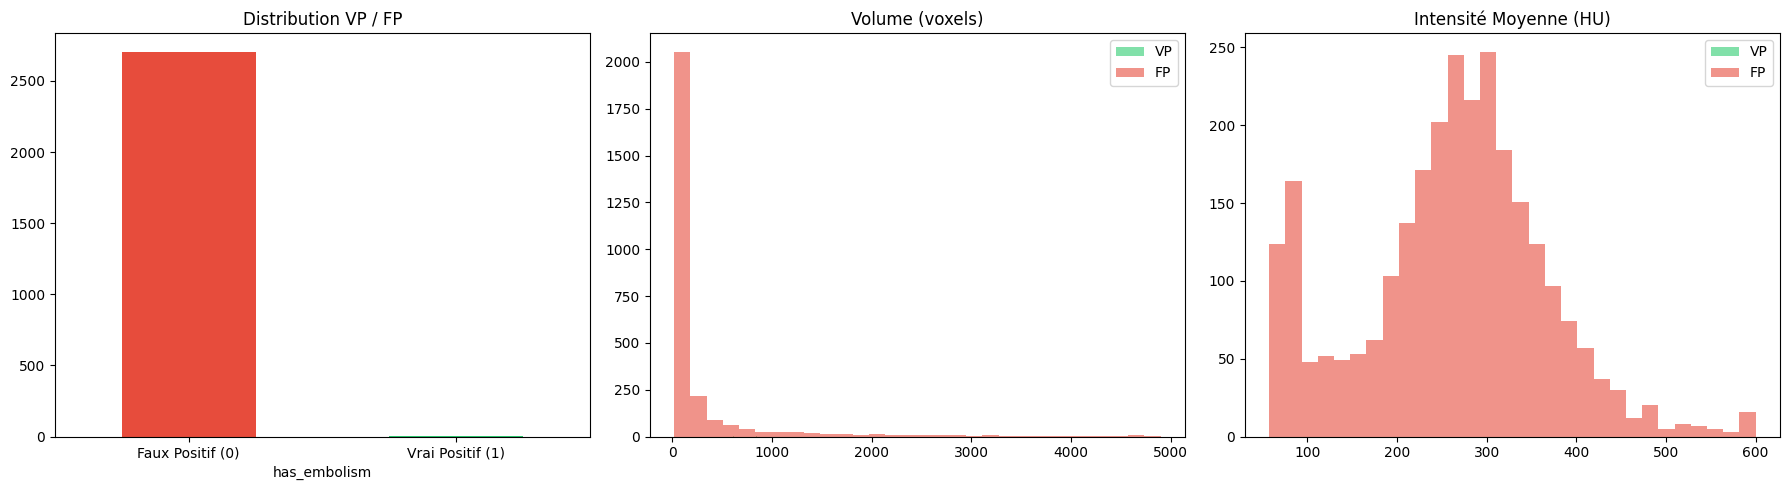

In [3]:
if output_csv.exists():
    df_final = pd.read_csv(output_csv)
    
    print('📊 Distribution des classes :')
    print(df_final['has_embolism'].value_counts().rename({0: 'FP (Faux Positif)', 1: 'VP (Vrai Positif)'}))
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Distribution VP vs FP
    df_final['has_embolism'].value_counts().plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'])
    axes[0].set_title('Distribution VP / FP')
    axes[0].set_xticklabels(['Faux Positif (0)', 'Vrai Positif (1)'], rotation=0)

    # 2. Distribution du volume
    for label, color, name in [(1, '#2ecc71', 'VP'), (0, '#e74c3c', 'FP')]:
        subset = df_final[df_final['has_embolism'] == label]
        axes[1].hist(subset['volume_voxels'].dropna(), bins=30, alpha=0.6, color=color, label=name)
    axes[1].set_title('Volume (voxels)')
    axes[1].legend()

    # 3. Intensité moyenne
    for label, color, name in [(1, '#2ecc71', 'VP'), (0, '#e74c3c', 'FP')]:
        subset = df_final[df_final['has_embolism'] == label]
        axes[2].hist(subset['intensity_mean'].dropna(), bins=30, alpha=0.6, color=color, label=name)
    axes[2].set_title('Intensité Moyenne (HU)')
    axes[2].legend()

    plt.tight_layout()
    plt.show()